In [1]:
# Set up google colab
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Setup cell
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

%matplotlib inline
plt.rcParams["figure.figsize"] = (10.0, 8.0) # Set default size of plots
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gray"

# 1. Data Reading and Pre-processing

In [6]:
# Pre-processing Cell
# Reads data and processes it in exact same way as in arima.ipynb
# Read Weather dataset
df = pd.read_csv('/content/drive/MyDrive/mpi_roof_2025.csv', encoding = "unicode_escape")

# Selecting only 'Date Time' and 'T(degC)'
df = df[['Date Time', 'T (degC)']]

# Dropping potential NA values
df = df.dropna()

# Converting to proper date time format
df["Date Time"] = pd.to_datetime(df["Date Time"], format = "mixed")
df = df.set_index("Date Time").asfreq("10min")

# Select rows for short-term forecasting
# Total of 72 hours
df_short = df["2025-01-01":"2025-01-05"]

# Select rows for long-term forecasting
# Total of 5 months
df_long = df["2025-01-01":"2025-05-31"]

# 2. Short-term Forecasting

In [15]:
# Train/test split
# Training: 48 hours
# Testing: 24 hours
train = df_short["2025-01-01":"2025-01-04 23:50:00"]
test  = df_short["2025-01-05":"2025-01-05 23:50:00"]

# Resampling into 1hr intervals
train_hourly = train.resample("1h").mean()
test_hourly  = test.resample("1h").mean()

train_vals = train_hourly["T (degC)"].values.reshape(-1, 1)
test_vals  = test_hourly["T (degC)"].values.reshape(-1, 1)

# Scale to [0,1]
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_vals)
test_scaled  = scaler.transform(test_vals)

# Create sequences
def create_sequences(data, seq_len):
    X, y = [], []
    for i in range(len(data) - seq_len):
        X.append(data[i : i + seq_len])
        y.append(data[i + seq_len])
    return torch.tensor(np.array(X), dtype=torch.float32), \
           torch.tensor(np.array(y), dtype=torch.float32)

SEQ_LEN = 24  # use last 24 hours to predict next step (was 144 at 10-min)

X_train, y_train = create_sequences(train_scaled, SEQ_LEN)
X_test,  y_test  = create_sequences(
    np.concatenate([train_scaled[-SEQ_LEN:], test_scaled]), SEQ_LEN
)

print(f"X_train: {X_train.shape}")  # (431, 144, 1)
print(f"X_test:  {X_test.shape}")   # (144, 144, 1)

X_train: torch.Size([72, 24, 1])
X_test:  torch.Size([24, 24, 1])


In [16]:
# LSTM Architecture
class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=2, dropout=0.2):
        super(LSTMModel, self).__init__()
        self.lstm = nn.LSTM(input_size,
                            hidden_size,
                            num_layers,
                            batch_first=True,
                            dropout=dropout)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])  # take last timestep

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model     = LSTMModel().to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

Using device: cpu


In [17]:
# Training
EPOCHS     = 50
BATCH_SIZE = 32

dataset    = torch.utils.data.TensorDataset(X_train, y_train)
dataloader = torch.utils.data.DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

train_losses = []

for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0
    for X_batch, y_batch in dataloader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        loss = criterion(model(X_batch), y_batch)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(dataloader)
    train_losses.append(avg_loss)
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} | Loss: {avg_loss:.6f}")

Epoch 10/50 | Loss: 0.061745
Epoch 20/50 | Loss: 0.052740
Epoch 30/50 | Loss: 0.055683
Epoch 40/50 | Loss: 0.036628
Epoch 50/50 | Loss: 0.035380


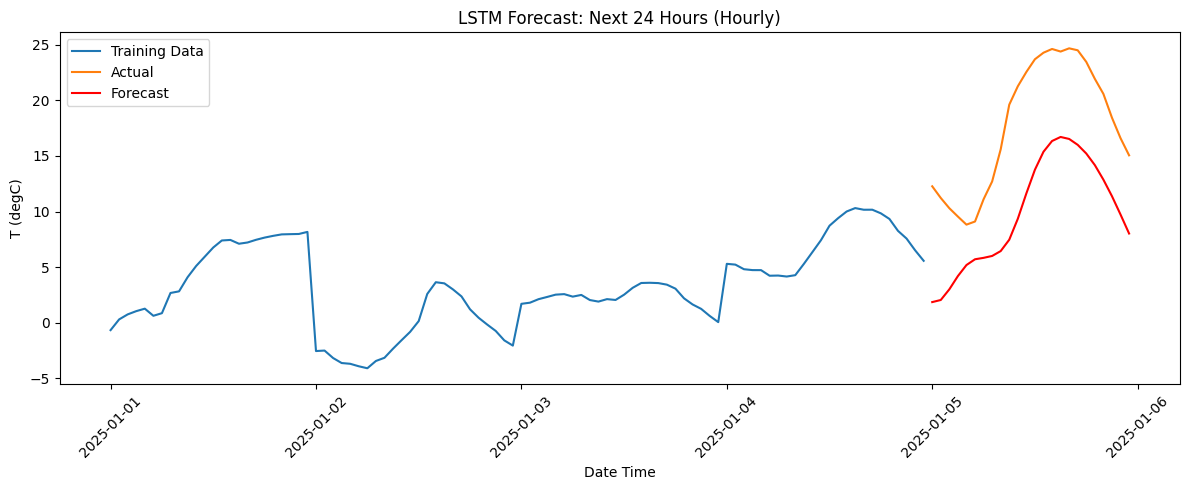

In [20]:
# Forecasting
model.eval()
with torch.no_grad():
    preds_scaled = model(X_test.to(device)).cpu().numpy()

preds = scaler.inverse_transform(preds_scaled)
actual = scaler.inverse_transform(y_test.numpy())

# Plotting
plt.figure(figsize=(12, 5))
plt.plot(train_hourly.index, train_hourly["T (degC)"], label="Training Data")
plt.plot(test_hourly.index,  test_hourly["T (degC)"],  label="Actual")
plt.plot(test_hourly.index,  preds,                    label="Forecast", color="red")
plt.title("LSTM Forecast: Next 24 Hours (Hourly)")
plt.xlabel("Date Time")
plt.ylabel("T (degC)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
# Evaluating 
rmse = np.sqrt(mean_squared_error(actual, preds))
print(f"RMSE: {rmse:.3f}")

RMSE: 8.275


In [21]:
# Saving forecasting results to CSV
lstm_results = pd.DataFrame({
    "actual":   test_hourly["T (degC)"].values,
    "forecast": preds.flatten()
}, index=test_hourly.index)

lstm_results.to_csv("/content/drive/MyDrive/lstm_results.csv")